# Фреймворк, критик, голосование: что окупается

Третий этап проекта. Берём ReAct-агента из первого этапа и надстраиваем над ним то, что обещает прирост: фреймворк LangGraph, критика, голосование с каскадом. Каждая надстройка стоит денег, и фреймворк тоже, даже если ничего не добавляет к качеству. Поэтому через весь ноутбук ведём **одну таблицу денег**: сколько вызовов, токенов и центов уходит на вопрос и сколько ответов верны.

Тезис проекта прежний: **дешёвая модель с хорошими инструментами отвечает на свежие вопросы не хуже сильной, а верный ответ у неё стоит в разы меньше.** Вопрос этапа: сколько из этой экономии съедает фреймворк и какой паттерн окупается.

## Что нужно

Ключ OpenRouter в файле `.env` в корне проекта, как на прошлых этапах. Вопросы из `data/fresh_2026.jsonl`. Агент ходит в живую Википедию и на новостные сайты, поэтому нужен интернет.

Ноутбук не тратит деньги повторно: ответ и счётчик каждого вопроса сохраняются в `traces/<вариант>/<модель>/<вопрос>.json`, при повторном запуске берутся оттуда. Название варианта начинается с номера этапа и порядкового номера, например `s3-1-ReAct + счётчик HTTP`.

In [1]:
import os, re, json, time, contextvars, html
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from typing import Literal
import httpx
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
KEY = os.getenv("OPENROUTER_API_KEY")
assert KEY, "нет ключа: положите его в .env в корне проекта"

BASE_URL = "https://openrouter.ai/api/v1"
CHEAP, MID, STRONG = "openai/gpt-4o-mini", "anthropic/claude-haiku-4.5", "anthropic/claude-sonnet-4.6"
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent   # ноутбук лежит в notebooks/
DATA, TRACES, IMG = ROOT / "data", ROOT / "traces", ROOT / "img" / "03"
IMG.mkdir(parents=True, exist_ok=True)
STRONG_SAMPLE = 57                    # сколько вопросов гоняем на сильной модели

def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

def pmap(fn, items, workers=6):
    # copy_context: каждый поток получает текущий номер вопроса QID, иначе счётчик не поймёт, чей это вызов
    with ThreadPoolExecutor(workers) as ex:
        futures = [ex.submit(contextvars.copy_context().run, fn, item) for item in items]
        return [f.result() for f in futures]

## Спринт 1. Счётчик: что уходит в сеть

ReAct-цикл и LangGraph внутри ходят в сеть через библиотеку `httpx`. Если дать им один и тот же `httpx.Client` с крючком на ответ, мы увидим каждый вызов модели, чей бы код его ни сделал. Это как кассовый чек на выходе: неважно, кто набрал корзину, чек пробивается один и тот же.

Крючок получает ответ, а у ответа есть исходный запрос. Из запроса берём модель, число сообщений и инструментов, из ответа поле `usage`: токены на входе, на выходе и цену, которую OpenRouter возвращает сам в `usage.cost`. Каждый вызов помечаем текущей меткой конфигурации `TAG` и номером вопроса `QID`. По метке потом складываем деньги, по номеру сохраняем вызовы вопроса в его трейс. Первый запрос под каждой меткой сохраняем целиком: по нему видно, какой системный промпт подложила библиотека.

Поэтому `chat` ходит в сеть через этот клиент и сам ничего не записывает: всё пишет крючок, и в счётчик попадают и вызовы, которые делает LangGraph.

In [2]:
CALLS, FIRST, TAG = [], {}, {"now": "без метки"}
QID = contextvars.ContextVar("QID", default=None)

In [3]:
def on_response(response):
    request = response.request
    if not request.url.path.endswith("/chat/completions") or response.status_code != 200:
        return                                  # неудачные попытки не считаем: за них не платят
    response.read()                             # крючок вызывается до чтения тела, читаем сами
    body, usage = json.loads(request.content), response.json().get("usage") or {}
    tag = TAG["now"]
    FIRST.setdefault(tag, body)
    CALLS.append({"tag": tag, "qid": QID.get(), "model": body["model"].split("/")[-1],
                  "messages": len(body["messages"]), "tools": len(body.get("tools") or []),
                  "prompt": usage.get("prompt_tokens", 0), "completion": usage.get("completion_tokens", 0),
                  "cost": usage.get("cost") or 0.0})

In [4]:
HTTP = httpx.Client(event_hooks={"response": [on_response]}, timeout=180)
HEADERS = {"Authorization": f"Bearer {KEY}", "X-Title": "ai-agent-events"}

def chat(messages, model=CHEAP, tools=None, temperature=0.0, attempts=5):
    body = {"model": model, "messages": messages, "temperature": temperature}
    if tools:
        body["tools"] = tools
    for attempt in range(attempts):
        r = HTTP.post(f"{BASE_URL}/chat/completions", json=body, headers=HEADERS)
        if r.status_code == 200:
            return r.json()["choices"][0]["message"]
        time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"HTTP {r.status_code}: {r.text[:200]}")

In [ ]:
# проверка счётчика: один живой вызов, около 0.0003 цента;
# TAG["now"] = "проверка счётчика"
# chat([{"role": "user", "content": "Say OK"}])
# pd.DataFrame(CALLS)

,tag,qid,model,messages,tools,prompt,completion,cost
0,проверка счётчика,None,gpt-4o-mini,1,0,9,2,0.000003


## Спринт 2. Агент первого этапа и baseline

Агент тот же, что в первом этапе, в варианте «все источники + чтение страницы»: четыре поиска (английская и русская Википедия, GEN, ESPN) и `page_find`, который ищет предложения с ключевыми словами в полном тексте найденной статьи. Текст статей ESPN берётся из открытого API ESPN по номеру статьи из результатов поиска: сама страница статьи отвечает пустой страницей (защита от ботов). Инструменты ходят в Википедию и на сайты через `requests`, мимо счётчика: они бесплатны, считаем только вызовы модели.

In [5]:
WIKI = "https://en.wikipedia.org/w/api.php"
RU_WIKI = "https://ru.wikipedia.org/w/api.php"
WIKI_HEADERS = PAGE_HEADERS = {"User-Agent": "ai-agent-events/0.1 (https://github.com/NorthMarshmallo)"}

def wiki(params, attempts=3):
    for attempt in range(attempts):
        try:
            r = requests.get(WIKI, params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=15)
            if r.status_code == 200 and r.headers.get("content-type", "").startswith("application/json"):
                return r.json()["query"]
            error = f"ответила {r.status_code}"
        except requests.RequestException as e:
            error = f"недоступна: {type(e).__name__}"
        time.sleep(1.0 + attempt)
    raise RuntimeError(f"Википедия {error}")

def get_page(url, site, params=None, attempts=3):
    for attempt in range(attempts):
        try:
            r = requests.get(url, params=params, headers=PAGE_HEADERS, timeout=15)
            if r.status_code == 200:
                return r
            error = f"ответил {r.status_code}"
        except requests.RequestException as e:
            error = f"недоступен: {type(e).__name__}"
        time.sleep(1.0 + attempt)
    raise RuntimeError(f"{site} {error}")

def clean(markup):
    markup = re.sub(r"(?s)<(style|script)[^>]*>.*?</\1>", "", markup)
    return " ".join(html.unescape(re.sub(r"<[^>]+>", " ", markup)).split())

def en_wiki_article(title):
    page = next(iter(wiki({"action": "query", "prop": "extracts", "explaintext": 1, "redirects": 1, "titles": title})["pages"].values()))
    return None if "missing" in page else (page["title"], page.get("extract", ""))

def ru_wiki_article(title):
    page = get_page(RU_WIKI, "Русская Википедия", {"action": "parse", "page": title, "prop": "text", "redirects": 1, "format": "json", "formatversion": 2}).json()
    if "parse" not in page:
        return None
    return page["parse"]["title"], clean(page["parse"]["text"]).replace("[ править | править код ]", "")

def gen_article(query):
    posts = get_page("https://www.genengnews.com/wp-json/wp/v2/posts", "GEN", {"search": query, "orderby": "relevance", "per_page": 5, "_fields": "title,content"}).json()
    if not posts:
        return None
    post = next((p for p in posts if clean(p["title"]["rendered"]) == query), posts[0])
    return clean(post["title"]["rendered"]), clean(post["content"]["rendered"])

def espn_article(query):
    results = get_page("https://site.web.api.espn.com/apis/search/v2", "ESPN", {"query": query, "limit": 5}).json().get("results", [])
    articles = [c for r in results if r.get("type") == "article" for c in r["contents"]]
    if not articles:
        return None
    article = next((a for a in articles if a["displayName"] == query), articles[0])
    story = get_page(f"https://content.core.api.espn.com/v1/sports/news/{article['id']}", "ESPN").json()["headlines"][0]["story"]
    return article["displayName"], clean(story)

def preview(article):
    return f"[{article[0]}] {article[1][:5000]}" if article else "No data"

def web_search(query: str) -> str:
    hits = wiki({"action": "query", "list": "search", "srsearch": query, "srlimit": 1})["search"]
    if not hits:
        return "No data"
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "exintro": 1, "titles": hits[0]["title"]})["pages"]
    text = " ".join(next(iter(pages.values())).get("extract", "").split())
    return f"[{hits[0]['title']}] {text[:5000]}"

def ru_wiki_search(query: str) -> str:
    hits = get_page(RU_WIKI, "Русская Википедия", {"action": "query", "list": "search", "srsearch": query, "srlimit": 1, "format": "json"}).json()["query"]["search"]
    return preview(ru_wiki_article(hits[0]["title"]) if hits else None)

def gen_search(query: str) -> str:
    return preview(gen_article(query))

def espn_search(query: str) -> str:
    return preview(espn_article(query))

ARTICLES = {"en_wiki": en_wiki_article, "ru_wiki": ru_wiki_article, "gen": gen_article, "espn": espn_article}

def page_find(title: str, keywords: list[str], site: str = "en_wiki") -> str:
    article = ARTICLES[site](title)
    if not article:
        return f"Статья {title} не найдена"
    sentences = re.split(r"(?<=[.!?])\s+|\n+", article[1])
    found = [s for s in sentences if any(k.lower() in s.lower() for k in keywords)]
    return "\n".join(found) if found else "No data"

Описания инструментов и аргументов те же, что в первом этапе, и собираются той же функцией `register`: схема параметров берётся из Pydantic-модели, ею же проверяются аргументы, которые прислала модель. Эти описания понадобятся ещё раз в LangGraph: там мы проверим, дошли ли они до модели.

In [6]:
class SearchArgs(BaseModel):
    query: str = Field(description="короткий поисковый запрос: имя, название, термин")

class FindArgs(BaseModel):
    title: str = Field(description="название статьи из квадратных скобок в ответе поиска, например 2026 in Japan")
    keywords: list[str] = Field(description="ключевые слова для поиска предложений в статье: имена, места, даты, например ['Haneda', 'August 24']")
    site: Literal["en_wiki", "ru_wiki", "gen", "espn"] = Field("en_wiki", description="откуда статья: en_wiki после web_search, ru_wiki после ru_wiki_search, gen после gen_search, espn после espn_search")

TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "description": description, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}

register(web_search, SearchArgs, "Ищет статью в англоязычной Википедии и возвращает её вступление")
register(ru_wiki_search, SearchArgs, "Ищет статью в русской Википедии и возвращает название и начало статьи. Запрос пишется по-русски, продолжение статьи ищи через page_find с site=ru_wiki")
register(gen_search, SearchArgs, "Ищет статью на GEN (Genetic Engineering & Biotechnology News) про биотех и AI в биологии и возвращает название и начало статьи. Запрос пишется по-английски, продолжение статьи ищи через page_find с site=gen")
register(espn_search, SearchArgs, "Ищет спортивную новость на ESPN и возвращает название и начало статьи. Запрос пишется по-английски, продолжение статьи ищи через page_find с site=espn")
register(page_find, FindArgs, "Ищет предложения с ключевыми словами в полном тексте статьи, которую нашёл инструмент поиска. Нужна, когда во вступлении из поиска ответа нет: передай название статьи из квадратных скобок и сайт, где она найдена")
REACT_TOOLS = [spec["schema"] for spec in TOOLS.values()]

assert web_search("Scott Derrickson").startswith("[Scott Derrickson]")
assert "injuring nine people" in page_find("2026 in Japan", ["Haneda"])
list(TOOLS)

['web_search', 'ru_wiki_search', 'gen_search', 'espn_search', 'page_find']

Цикл агента первого этапа, собранный в одну функцию. Поведение то же: системный промпт `SYSTEM` с ответом в строке `FINAL:`, не больше восьми шагов, повторный вызов инструмента с теми же аргументами останавливает цикл. Когда сработало стоп-условие, модель делает последний шаг без инструментов и отвечает тем, что уже нашла. Ошибка инструмента возвращается модели текстом, а результат обрезается до 2000 символов.

Температура 0, чтобы разница между конфигурациями меньше зависела от случайности. Голосование дальше поднимет её явно. Фраза последнего шага `LAST_STEP` повторяет просьбу отвечать на языке вопроса: без неё после обрыва цикла модель отвечает по-русски (разбор fresh-104 в `docs/01-react-agent.md`).

In [7]:
SYSTEM = ("Ты решаешь задачи. Если нужно посчитать или найти факт, вызывай инструменты, а не угадывай. "
          "Когда ответ готов, напиши его последней строкой в формате FINAL: <ответ>. "
          "Для числовых задач в FINAL только число, для вопросов о фактах короткая фраза "
          "на языке вопроса, имена и названия пиши как в источнике.")
LAST_STEP = ("Инструменты больше недоступны. Ответь по тому, что уже известно, последней строкой FINAL: <ответ> "
             "на языке вопроса, имена и названия пиши как в источнике.")
MAX_STEPS = 8

def run_tool(call):
    name = call["function"]["name"]
    try:
        spec = TOOLS[name]
        args = spec["args"].model_validate_json(call["function"]["arguments"])
        result = spec["fn"](**args.model_dump())
    except Exception as e:
        result = f"НЕ удалось вызвать инструмент {name}: {e}"
    return {"role": "tool", "tool_call_id": call["id"], "content": str(result)[:2000]}

def react_agent(question, model=CHEAP, temperature=0.0, max_steps=MAX_STEPS):
    messages, seen = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}], set()
    for step in range(1, max_steps + 1):
        msg = chat(messages, model, REACT_TOOLS, temperature)
        messages.append(msg)
        calls = msg.get("tool_calls") or []
        if not calls:
            return msg.get("content") or "", messages
        keys = [(c["function"]["name"], c["function"]["arguments"]) for c in calls]
        if any(k in seen for k in keys) or step == max_steps:      # повтор или лимит шагов: последний шаг без инструментов
            messages[-1] = {"role": "user", "content": LAST_STEP}
            msg = chat(messages, model, None, temperature)
            messages.append(msg)
            return msg.get("content") or "", messages
        seen.update(keys)
        messages += [run_tool(c) for c in calls]

Проверка ответа та же, что в первом этапе: `normalize` приводит к одному виду числа и даты, в том числе по-русски, а `is_correct` засчитывает ответ, если в нём есть каждая часть эталона. `final_answer` берёт текст после `FINAL:`.

In [8]:
MONTHS = ["january", "february", "march", "april", "may", "june", "july", "august", "september", "october", "november", "december"]
RU_MONTHS = dict(zip(["январ", "феврал", "март", "апрел", "ма", "июн", "июл", "август", "сентябр", "октябр", "ноябр", "декабр"], MONTHS))
NUMBERS = {w: str(i) for i, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen seventeen eighteen nineteen twenty".split())}
NUMBERS.update({w: str(10 * i) for i, w in enumerate("thirty forty fifty sixty seventy eighty ninety".split(), 3)})
NUMBERS.update({w: str(i) for i, w in enumerate("ноль один два три четыре пять шесть семь восемь девять десять одиннадцать двенадцать тринадцать четырнадцать пятнадцать шестнадцать семнадцать восемнадцать девятнадцать двадцать".split())})
NUMBERS.update({w: str(10 * i) for i, w in enumerate("тридцать сорок пятьдесят шестьдесят семьдесят восемьдесят девяносто".split(), 3)})
NUMBERS.update({"одна": "1", "две": "2"})
SCALES = {"thousand": 1e3, "тысяча": 1e3, "тысячи": 1e3, "тысяч": 1e3, "тыс": 1e3,
          "million": 1e6, "m": 1e6, "миллион": 1e6, "миллиона": 1e6, "миллионов": 1e6, "млн": 1e6,
          "billion": 1e9, "bn": 1e9, "миллиард": 1e9, "миллиарда": 1e9, "миллиардов": 1e9, "млрд": 1e9}

def normalize(text):
    text = str(text).lower().replace("ё", "е")
    text = re.sub(r"\b\d{1,3}(?:[   ]\d{3})+\b", lambda m: re.sub(r"\D", "", m[0]), text)
    text = re.sub(r"(\d),(?=\d{3}\b)", r"\1", text).replace(",", ".") if re.search(r"\d,\d", text) else text
    text = re.sub(r"\b(\d{4})-(\d{2})-(\d{2})\b", lambda m: f"{int(m[3])} {MONTHS[int(m[2]) - 1]} {m[1]}", text)
    text = re.sub(r"\b(" + "|".join(RU_MONTHS) + r")(?:я|а|е|ь|й)?\b", lambda m: RU_MONTHS[m[1]], text)
    text = re.sub(r"\b(" + "|".join(NUMBERS) + r")\b", lambda m: NUMBERS[m[1]], text)
    text = re.sub(r"(\d+(?:\.\d+)?)\s*(" + "|".join(SCALES) + r")(?!\w)", lambda m: str(round(float(m[1]) * SCALES[m[2]])), text)
    text = re.sub(r"(\d)(st|nd|rd|th|-?[а-я]{1,2})\b", r"\1", text)
    text = re.sub(r"(\d+)\.(\d+)", lambda m: m[1] + ("_" + m[2].rstrip("0") if m[2].strip("0") else ""), text)
    text = re.sub(r"(\d) of ", r"\1 ", text)
    text = re.sub(r"[^\w\s]", " ", text.replace(",", ""))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    text = re.sub(r"\b(" + "|".join(MONTHS) + r") (\d{1,2})\b", r"\2 \1", " ".join(text.split()))
    return text

def part_correct(gold, answer):
    number = re.fullmatch(r"(?:at least |about |over |more than )?(\d+(?:_\d+)?)(?: [^\W\d]+)*", gold)
    if number and not any(m in gold for m in MONTHS):
        return number[1] in answer.split()
    return gold in answer

def final_answer(text):
    m = re.search(r"FINAL:\s*(.+)", text or "")
    return m.group(1).strip() if m else (text or "").strip()

def is_correct(task, answer):
    answer = normalize(final_answer(answer))
    return all(part_correct(normalize(p), answer) for p in task["answer"].split(", "))   # ответ из нескольких частей проверяем по частям

assert is_correct({"answer": "15 March"}, "Нашёл.\nFINAL: March 15, 2026")
assert not is_correct({"answer": "Charles H. Bennett, Gilles Brassard"}, "FINAL: Charles H. Bennett")
"is_correct работает"

'is_correct работает'

`run_config` прогоняет конфигурацию по вопросам параллельно под своей меткой. Перед каждым вопросом ставит `QID`, чтобы счётчик знал, чей вызов. Ответ, вызовы модели из счётчика и сообщения диалога пишет в `traces/<вариант>/<модель>/<вопрос>.json`. Если трейс уже есть, модель не вызывается: ответ берётся из трейса, а его вызовы возвращаются в `CALLS`, поэтому таблица собирается и без повторных трат. Функция агента возвращает ответ и сообщения или просто ответ.

`report` складывает деньги из `CALLS` в таблицу с колонками этапа: доля верных, вызовов, токенов и центов на вопрос, центов за верный ответ. Верность пересчитывается при каждом вызове: если поправить `is_correct`, таблица обновится без перезапуска агентов. `wrong` показывает ответы, которые проверка сочла неверными.

Вопросы: 57 вопросов, на которых гонялись все конфигурации первого этапа, - первые 27 из исходного набора и 30 собственных (`fresh-125`...`fresh-154`).

In [9]:
tasks = load_jsonl("fresh_2026.jsonl")[:27] + load_jsonl("fresh_2026.jsonl")[125:]
TASKS = {t["id"]: t for t in tasks}
RESULTS = {}

def to_json(messages):
    return [m if isinstance(m, dict) else m.model_dump(exclude_none=True) for m in messages]

def key(variant, model=CHEAP):
    return f"{variant} | {model.split('/')[-1]}"

def run_config(variant, fn, model=CHEAP, sample=None, workers=6, rerun=False):
    sample = sample or tasks
    tag = TAG["now"] = key(variant, model)
    folder = TRACES / variant / model.split("/")[-1]
    folder.mkdir(parents=True, exist_ok=True)
    CALLS[:] = [c for c in CALLS if c["tag"] != tag]          # повторный запуск ячейки не удваивает счёт
    def one(task):
        path = folder / f"{task['id']}.json"
        if path.exists() and not rerun:
            t = json.loads(path.read_text(encoding="utf-8"))
            CALLS.extend({**c, "tag": tag} for c in t["calls"])   # метка из текущего имени, а не из сохранённого
            return t["answer"]
        QID.set(task["id"])
        try:
            out = fn(task["question"], model)
            answer, messages = out if isinstance(out, tuple) else (out, [])
        except Exception as e:                                   # сбой сети или API: не сохраняем, при следующем запуске вопрос пройдёт заново
            return f"ошибка: {type(e).__name__}: {e}"[:300]
        calls = [c for c in CALLS if c["tag"] == tag and c["qid"] == task["id"]]
        path.write_text(json.dumps({"task": task, "answer": answer, "calls": calls, "messages": to_json(messages)},
                                   ensure_ascii=False, indent=1), encoding="utf-8")
        return answer
    answers = pmap(one, sample, workers)
    RESULTS[tag] = [{"id": t["id"], "answer": a} for t, a in zip(sample, answers)]
    return report([tag])

def report(tags=None):
    rows = []
    for tag in tags or RESULTS:
        res, calls = RESULTS[tag], [c for c in CALLS if c["tag"] == tag]
        n, ok, cost = len(res), sum(is_correct(TASKS[r["id"]], r["answer"]) for r in res), sum(c["cost"] for c in calls)
        variant, model = tag.split(" | ")
        rows.append({"вариант": variant, "модель": model, "верно": f"{ok}/{n}", "доля": round(ok / n, 3), "вызовов на вопрос": round(len(calls) / n, 1),
                     "токенов на вопрос": round(sum(c["prompt"] + c["completion"] for c in calls) / n),
                     "центов на вопрос": round(cost / n * 100, 4), "центов за верный": round(cost / ok * 100, 4) if ok else None})
    return pd.DataFrame(rows)

def wrong(variant, model=CHEAP, n=10):
    tag = key(variant, model)
    return pd.DataFrame([{"id": r["id"], "эталон": TASKS[r["id"]]["answer"], "ответ": final_answer(r["answer"])[:110]}
                         for r in RESULTS[tag] if not is_correct(TASKS[r["id"]], r["answer"])][:n])

len(tasks)

57

In [10]:
table = run_config("s3-1-ReAct + счётчик HTTP", react_agent)
first = RESULTS[key("s3-1-ReAct + счётчик HTTP")][0]                # первый вопрос: ответ агента рядом с эталоном
print(final_answer(first["answer"]), "| эталон:", TASKS[first["id"]]["answer"])
table

March 15, 2026 | эталон: 15 March


,вариант,модель,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,s3-1-ReAct + счётчик HTTP,gpt-4o-mini,29/57,0.509,5.4,7385,0.0954,0.1875


In [11]:
wrong("s3-1-ReAct + счётчик HTTP", n=20)

,id,эталон,ответ
0,fresh-2,Miguel Díaz-Canel,Iran
1,fresh-4,A total fire ban,закон о запрете на использование одноразового ...
2,fresh-6,"4,500",519
3,fresh-7,Deniz Göktaş,Нет информации.
4,fresh-10,Twelve,11
5,fresh-12,"700,000","более 1,5 миллиона детей"
6,fresh-13,41.5 °C,34 °C
7,fresh-17,EOS-05,Нет информации о запуске ISRO 3 сентября 2026 ...
8,fresh-18,13 July,Дата неизвестна.
9,fresh-19,Disney Kids & Family,Информация отсутствует.


## Спринт 3. LangGraph

Функция `create_agent` из LangChain собирает ReAct-цикл в виде графа LangGraph. В графе два узла, «модель» и «инструменты», и правило перехода: если модель попросила инструмент, граф идёт в узел инструментов и возвращается к модели, если нет, работа закончена. Граф строится один раз, на каждом шаге меняется только список сообщений, который он носит с собой.

Модель подключаем через `ChatOpenAI` с адресом OpenRouter и клиентом `http_client=HTTP`, так вызовы LangGraph попадают в тот же счётчик.

Как инструменты и правила ReAct переносятся в LangGraph:
- инструмент описывается функцией `tool`. Описание берём из `TOOLS`: у наших функций нет докстрингов, из которых `tool` взял бы его сам;
- `safe` делает то же, что `run_tool` в ReAct: ошибка инструмента возвращается модели текстом, результат обрезается до 2000 символов. Сам LangGraph возвращает модели только ошибки в аргументах, а любая другая, например недоступный сайт, останавливает прогон вопроса. Для ошибок есть готовый слой `ToolErrorMiddleware`, но обрезку всё равно пришлось бы делать отдельно, поэтому оставляем одну функцию;
- системный промпт тот же `SYSTEM`, температура 0, ответ берём из строки `FINAL:`.

`run_langgraph` возвращает весь список сообщений: в нём и ответ, и то, что вернули инструменты, это понадобится критику. `ask_langgraph` отдаёт ответ и сообщения в `run_config`.

In [12]:
import functools
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.tools import tool

def safe(fn):
    @functools.wraps(fn)                         # сохраняем имя и подсказки типов: по ним tool строит схему
    def wrapped(*args, **kwargs):
        try:
            return str(fn(*args, **kwargs))[:2000]
        except Exception as e:
            return f"НЕ удалось вызвать инструмент {fn.__name__}: {e}"
    return wrapped

LC_TOOLS = [tool(safe(spec["fn"]), description=spec["description"]) for spec in TOOLS.values()]
LG_MIDDLEWARE = []

def lc_model(model=CHEAP, temperature=0.0):
    return ChatOpenAI(model=model, base_url=BASE_URL, api_key=KEY, http_client=HTTP, temperature=temperature)

In [13]:
def run_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    agent = create_agent(lc_model(model, temperature), tools=LC_TOOLS, system_prompt=SYSTEM + extra, middleware=LG_MIDDLEWARE)
    return agent.invoke({"messages": [{"role": "user", "content": question}]})["messages"]

def ask_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    messages = run_langgraph(question, model, temperature, extra)
    return messages[-1].content, messages

### Проба первого запроса: что программа отправляет модели сама

ReAct и LangGraph получают одинаковые исходные данные: системный промпт `SYSTEM`, описания пяти инструментов и вопрос. Но запрос к модели каждая программа собирает сама, и фреймворк по пути может что-то добавить (свой текст, служебные поля), убрать или переформатировать. Чтобы это увидеть, задаём обоим простой вопрос «2 + 2» и смотрим на первый вызов, каким он ушёл в сеть:
- первый вызов, потому что в нём ещё нет результатов поиска: он зависит только от того, как программа собрала запрос;
- простой вопрос, потому что почти все токены приходятся на постоянную часть, промпт и схемы инструментов;
- на уровне HTTP, потому что именно это получает провайдер и за это берёт деньги.

Разница в токенах первого запроса и есть то, что фреймворк подложил или выбросил сам. Это вес одного вызова; сколько вызовов фреймворк делает на вопрос, видно только в полной строке таблицы. `probe` сохраняет первый запрос в `traces/s3-2-проба первого запроса/<модель>/<вариант>.json`, при повторном запуске берёт его оттуда, без вызова модели.

Первым пробуем LangGraph, где инструменты обёрнуты в `tool` без схемы аргументов: «LangGraph без описаний аргументов». Полный прогон на вопросах для него не нужен: что теряется, видно уже по схеме в первом запросе.

In [14]:
PROBE = "What is 2 + 2? Reply with the number only."

def probe(variant, fn, model=CHEAP):
    tag = TAG["now"] = f"проба первого запроса: {variant}"
    path = TRACES / "s3-2-проба первого запроса" / model.split("/")[-1] / f"{variant}.json"
    CALLS[:] = [c for c in CALLS if c["tag"] != tag]
    if path.exists():
        t = json.loads(path.read_text(encoding="utf-8"))
        FIRST[tag] = t["first"]
        CALLS.extend({**c, "tag": tag} for c in t["calls"])
        return
    FIRST.pop(tag, None)
    QID.set("probe")
    fn(PROBE, model)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps({"first": FIRST[tag], "calls": [c for c in CALLS if c["tag"] == tag]}, ensure_ascii=False, indent=1), encoding="utf-8")

def probe_table():
    probes = pd.DataFrame([c for c in CALLS if c["tag"].startswith("проба первого запроса")])
    return probes.groupby("tag", sort=False).agg(вызовов=("prompt", "size"), первый_запрос=("prompt", "first"),
                                                 всего_токенов=("prompt", "sum"), центов=("cost", lambda s: round(s.sum() * 100, 4)))

probe("s3-1-ReAct + счётчик HTTP", react_agent)
probe("LangGraph без описаний аргументов + счётчик HTTP", ask_langgraph)
probe_table()

,вызовов,первый_запрос,всего_токенов,центов
tag,,,,
проба первого запроса: s3-1-ReAct + счётчик HTTP,3,614,2137,0.0352
проба первого запроса: LangGraph без описаний аргументов + счётчик HTTP,2,419,1053,0.0171


Сравниваем первые запросы байт в байт: какие поля тела запроса отличаются и что стало со схемой `page_find`, самого «многословного» инструмента.

In [15]:
def schema(tag, name):
    return next(t["function"] for t in FIRST[tag]["tools"] if t["function"]["name"] == name)

def compare_first(a, b):
    A, B = FIRST[f"проба первого запроса: {a}"], FIRST[f"проба первого запроса: {b}"]
    print("байт в запросе:", len(json.dumps(A, ensure_ascii=False)), "против", len(json.dumps(B, ensure_ascii=False)))
    for k in sorted(set(A) | set(B)):
        if k not in ("messages", "tools") and A.get(k) != B.get(k):
            print(f"поле {k}: {A.get(k)!r} против {B.get(k)!r}")
    print("системный промпт совпадает:", A["messages"][0] == B["messages"][0])
    for name in ("page_find", "web_search"):
        print(f"\n{name}\n  {a}: {json.dumps(schema('проба первого запроса: ' + a, name)['parameters'], ensure_ascii=False)}"
              f"\n  {b}: {json.dumps(schema('проба первого запроса: ' + b, name)['parameters'], ensure_ascii=False)}")

compare_first("s3-1-ReAct + счётчик HTTP", "LangGraph без описаний аргументов + счётчик HTTP")

байт в запросе: 3191 против 2304
поле stream: None против False
системный промпт совпадает: True

page_find
  s3-1-ReAct + счётчик HTTP: {"properties": {"title": {"description": "название статьи из квадратных скобок в ответе поиска, например 2026 in Japan", "title": "Title", "type": "string"}, "keywords": {"description": "ключевые слова для поиска предложений в статье: имена, места, даты, например ['Haneda', 'August 24']", "items": {"type": "string"}, "title": "Keywords", "type": "array"}, "site": {"default": "en_wiki", "description": "откуда статья: en_wiki после web_search, ru_wiki после ru_wiki_search, gen после gen_search, espn после espn_search", "enum": ["en_wiki", "ru_wiki", "gen", "espn"], "title": "Site", "type": "string"}}, "required": ["title", "keywords"], "title": "FindArgs", "type": "object"}
  LangGraph без описаний аргументов + счётчик HTTP: {"properties": {"title": {"type": "string"}, "keywords": {"items": {"type": "string"}, "type": "array"}, "site": {"default": "en_w

### Описания аргументов и правило остановки

Описания аргументов передаём схемой Pydantic через `args_schema`: это те же `SearchArgs` и `FindArgs`, что у ReAct.

Правило остановки ReAct добавляем промежуточным слоем (middleware). Это функция, которая оборачивает каждый вызов модели: получает запрос `ModelRequest` с историей `request.messages` и инструментами `request.tools`, может заменить его копией через `request.override(...)`, а `handler(request)` передаёт запрос модели.

Слой `stop_like_react` вызывает модель и смотрит на её ответ. Если модель снова просит инструмент с теми же аргументами, что уже были, или это восьмой шаг, а она всё ещё просит инструменты, ответ отбрасывается, и модель вызывается ещё раз, без инструментов и с фразой `LAST_STEP` в конце истории. Так у обоих агентов одинаковые правила остановки, и строки таблицы различаются только фреймворком. Этот же слой и жёсткий потолок: последний вызов идёт без инструментов, продолжить цикл модель не может, поэтому вызовов модели на вопрос не больше девяти, как у ReAct. Слой добавляем в `LG_MIDDLEWARE`, и с этого момента им пользуются все прогоны LangGraph.

Готовые слои LangChain здесь не подходят. `ToolCallLimitMiddleware` после заданного числа вызовов инструментов перестаёт их выполнять и просит модель словами больше их не вызывать, но повтор того же вызова не замечает, инструменты у модели не забирает и не просит ответить строкой `FINAL:` на языке вопроса. `ModelCallLimitMiddleware` при превышении лимита обрывает агента заглушкой «Model call limits exceeded», без ответа модели.

In [16]:
from langchain.agents.middleware import wrap_model_call
from langchain_core.messages import HumanMessage

LC_TOOLS = [tool(safe(spec["fn"]), description=spec["description"], args_schema=spec["args"]) for spec in TOOLS.values()]

def calls_of(message):
    return [(c["name"], json.dumps(c["args"], sort_keys=True)) for c in message.tool_calls]

@wrap_model_call
def stop_like_react(request, handler):
    response = handler(request)
    message = response.result[-1]
    seen = {k for m in request.messages if m.type == "ai" for k in calls_of(m)}   # вызовы, которые модель уже делала
    step = sum(m.type == "ai" for m in request.messages) + 1
    if message.tool_calls and (any(k in seen for k in calls_of(message)) or step == MAX_STEPS):
        response = handler(request.override(tools=[], messages=[*request.messages, HumanMessage(LAST_STEP)]))
    return response

LG_MIDDLEWARE.append(stop_like_react)

In [17]:
run_config("s3-3-LangGraph + счётчик HTTP", ask_langgraph)
probe("s3-3-LangGraph + счётчик HTTP", ask_langgraph)
compare_first("s3-1-ReAct + счётчик HTTP", "s3-3-LangGraph + счётчик HTTP")

байт в запросе: 3191 против 2967
поле stream: None против False
системный промпт совпадает: True

page_find
  s3-1-ReAct + счётчик HTTP: {"properties": {"title": {"description": "название статьи из квадратных скобок в ответе поиска, например 2026 in Japan", "title": "Title", "type": "string"}, "keywords": {"description": "ключевые слова для поиска предложений в статье: имена, места, даты, например ['Haneda', 'August 24']", "items": {"type": "string"}, "title": "Keywords", "type": "array"}, "site": {"default": "en_wiki", "description": "откуда статья: en_wiki после web_search, ru_wiki после ru_wiki_search, gen после gen_search, espn после espn_search", "enum": ["en_wiki", "ru_wiki", "gen", "espn"], "title": "Site", "type": "string"}}, "required": ["title", "keywords"], "title": "FindArgs", "type": "object"}
  s3-3-LangGraph + счётчик HTTP: {"properties": {"title": {"description": "название статьи из квадратных скобок в ответе поиска, например 2026 in Japan", "type": "string"}, "keywords

In [18]:
display(probe_table())
report([key(v) for v in ["s3-1-ReAct + счётчик HTTP", "s3-3-LangGraph + счётчик HTTP"]])

,вызовов,первый_запрос,всего_токенов,центов
tag,,,,
проба первого запроса: s3-1-ReAct + счётчик HTTP,3,614,2137,0.0352
проба первого запроса: LangGraph без описаний аргументов + счётчик HTTP,2,419,1053,0.0171
проба первого запроса: s3-3-LangGraph + счётчик HTTP,2,573,1361,0.0217


,вариант,модель,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,s3-1-ReAct + счётчик HTTP,gpt-4o-mini,29/57,0.509,5.4,7385,0.0954,0.1875
1,s3-3-LangGraph + счётчик HTTP,gpt-4o-mini,31/57,0.544,5.0,6410,0.0865,0.1590


In [19]:
wrong("s3-3-LangGraph + счётчик HTTP", n=30)

,id,эталон,ответ
0,fresh-2,Miguel Díaz-Canel,Iran
1,fresh-6,"4,500",519
2,fresh-10,Twelve,Неизвестно.
3,fresh-12,"700,000",Data not found.
4,fresh-13,41.5 °C,34 °C
5,fresh-17,EOS-05,Гаганьян
6,fresh-18,13 July,Неизвестно.
7,fresh-19,Disney Kids & Family,Disney Television Animation
8,fresh-21,Gavin Snider,Нет информации.
9,fresh-23,German Galushchenko,Andrii Ukrainets and Volodymyr Kompanichenko.


## Спринт 4. Потолок на деньги

Число вызовов модели на вопрос ограничено кодом, а не просьбой в промпте. У ReAct это цикл `for` на восемь шагов, у LangGraph слой `stop_like_react`: на восьмом шаге модель вызывается без инструментов и отвечает тем, что уже нашла. Больше девяти вызовов на вопрос не бывает ни у того, ни у другого.

`capped` находит вопросы, на которых потолок сработал: у них в счётчике девять вызовов модели. Для каждого показываем эталон и ответ, который агент дал после обрыва. `last_steps` печатает конец одного такого трейса: последние запросы к инструментам и итоговый ответ.

In [20]:
def capped(variant, model=CHEAP):
    tag = key(variant, model)
    calls = pd.Series([c["qid"] for c in CALLS if c["tag"] == tag]).value_counts()
    return pd.DataFrame([{"id": r["id"], "вызовов": calls[r["id"]], "эталон": TASKS[r["id"]]["answer"],
                          "ответ": final_answer(r["answer"])[:110], "верно": is_correct(TASKS[r["id"]], r["answer"])}
                         for r in RESULTS[tag] if calls.get(r["id"], 0) == MAX_STEPS + 1])

def last_steps(variant, qid, model=CHEAP, n=2):
    messages = json.loads((TRACES / variant / model.split("/")[-1] / f"{qid}.json").read_text(encoding="utf-8"))["messages"]
    asks = [m for m in messages if m.get("tool_calls")]
    print("вопрос:", TASKS[qid]["question"])
    for m in asks[-n:]:                                          # последние шаги, на которых модель ещё звала инструменты
        print("шаг", asks.index(m) + 1, "->", [(c["name"], c["args"]) for c in m["tool_calls"]])
    print("ответ после обрыва:", final_answer(messages[-1]["content"]), "| эталон:", TASKS[qid]["answer"])

cap_table = capped("s3-3-LangGraph + счётчик HTTP")
display(cap_table)
last_steps("s3-3-LangGraph + счётчик HTTP", cap_table.iloc[0]["id"])

,id,вызовов,эталон,ответ,верно
0,fresh-10,9,Twelve,Неизвестно.,False
1,fresh-18,9,13 July,Неизвестно.,False
2,fresh-19,9,Disney Kids & Family,Disney Television Animation,False
3,fresh-21,9,Gavin Snider,Нет информации.,False
4,fresh-125,9,ten-fold,Нет данных.,False
5,fresh-127,9,five,<нет данных>,False
6,fresh-129,9,Oak HC/FT and General Catalyst,Информация недоступна.,False
7,fresh-140,9,"Crouching Tiger, Hidden Dragon","""Avatar""",False
8,fresh-150,9,Nagoya,Япония,False
9,fresh-154,9,146.70,Информация недоступна.,False


вопрос: How many people were killed in the February 18 explosion at a fireworks store in China?
шаг 6 -> [('ru_wiki_search', {'query': 'взрыв в магазине фейерверков в Китае 18 февраля 2023'})]
шаг 7 -> [('web_search', {'query': 'February 18 2023 China fireworks store explosion news'})]
ответ после обрыва: Неизвестно. | эталон: Twelve


Для сравнения готовый слой `ModelCallLimitMiddleware` на том же вопросе: без нашего слоя и с потолком в три прохода через узел модели. Он не просит модель ответить, а обрывает граф и ставит вместо ответа свою заглушку. Это один живой прогон, около 0,1 цента; трейс сохраняется в `traces/s3-4-LangGraph с ModelCallLimitMiddleware/`, при повторном запуске ответ берётся оттуда.

In [21]:
from langchain.agents.middleware import ModelCallLimitMiddleware

def ask_call_limit(question, model=CHEAP, run_limit=3):
    agent = create_agent(lc_model(model), tools=LC_TOOLS, system_prompt=SYSTEM,
                         middleware=[ModelCallLimitMiddleware(run_limit=run_limit, exit_behavior="end")])
    messages = agent.invoke({"messages": [{"role": "user", "content": question}]})["messages"]
    return messages[-1].content, messages

qid = cap_table.iloc[0]["id"]
run_config("s3-4-LangGraph с ModelCallLimitMiddleware", ask_call_limit, sample=[TASKS[qid]])

,вариант,модель,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,s3-4-LangGraph с ModelCallLimitMiddleware,gpt-4o-mini,0/1,0.0,3.0,2007,0.0339,None


In [22]:
last_steps("s3-4-LangGraph с ModelCallLimitMiddleware", qid)

вопрос: How many people were killed in the February 18 explosion at a fireworks store in China?
шаг 2 -> [('page_find', {'title': 'List of fireworks accidents and incidents', 'keywords': ['February 18', 'explosion', 'fireworks store', 'China'], 'site': 'en_wiki'})]
шаг 3 -> [('web_search', {'query': 'February 18 2023 explosion fireworks store China casualties'})]
ответ после обрыва: Model call limits exceeded: run limit (3/3) | эталон: Twelve


## Спринт 5. Критик с опорой

Первый паттерн этапа. Критик не спрашивает модель «уверена ли ты», а сверяет ответ с тем, что агент реально нашёл за прогон: с результатами инструментов. Так ловится главная ошибка агента с поиском: поиск ничего не дал, а модель ответила по памяти.

Граф собираем руками: узел `answer` запускает агента LangGraph из спринта 3, узел `critic` проверяет ответ, правило `route` решает, куда дальше. Если критик ответ не подтвердил, агент получает замечание и ищет заново, но исправляться может не больше двух раз (`MAX_FIXES`). Вердикт приходит объектом `Verdict` через `with_structured_output`, а не текстом, который пришлось бы разбирать. Ход проверки по кругам (ответ, вердикт, замечание) сохраняется в трейс.

Счёт критика берётся из этого хода: сколько неверных первых ответов он довёл до верных и сколько верных испортил.

In [23]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

MAX_FIXES = 2

class QA(TypedDict):
    question: str
    model: str
    answer: str
    evidence: str
    feedback: str
    rounds: int
    trail: list

class Verdict(BaseModel):
    supported: bool = Field(description="true, только если находки прямо подтверждают ответ")
    issue: str = Field(description="что не так или чего не хватает; пусто, если ответ подтверждён")

CRITIC_SYSTEM = ("Ты проверяешь короткий ответ агента по его находкам: тому, что вернули поиск и чтение статей. "
                 "Суди только по находкам, не по своей памяти. Если в находках ответа нет или он с ними расходится, ответ не подтверждён.")

def answer_node(state):
    note = ""
    if state["feedback"]:
        note = f"\n\nПроверка отклонила твой прошлый ответ «{final_answer(state['answer'])}»: {state['feedback']} Поищи заново и исправь."
    messages = run_langgraph(state["question"] + note, state["model"])
    found = "\n".join(str(m.content)[:800] for m in messages if m.type == "tool")   # находки агента: что вернули инструменты
    return {"answer": messages[-1].content, "evidence": found[-4000:], "rounds": state["rounds"] + 1}

def critic_node(state):
    critic = lc_model(state["model"]).with_structured_output(Verdict)
    verdict = critic.invoke([{"role": "system", "content": CRITIC_SYSTEM},
                             {"role": "user", "content": f"Вопрос: {state['question']}\nОтвет: {final_answer(state['answer'])}\n\n"
                                                         f"Находки:\n{state['evidence'] or 'ничего не найдено'}"}])
    feedback = "" if verdict.supported else verdict.issue or "ответ не подтверждён находками"
    step = {"round": state["rounds"], "answer": final_answer(state["answer"]), "supported": verdict.supported, "issue": verdict.issue}
    return {"feedback": feedback, "trail": state["trail"] + [step]}

def route(state):
    return "answer" if state["feedback"] and state["rounds"] <= MAX_FIXES else END

graph = StateGraph(QA)
graph.add_node("answer", answer_node)
graph.add_node("critic", critic_node)
graph.add_edge(START, "answer")
graph.add_edge("answer", "critic")
graph.add_conditional_edges("critic", route, ["answer", END])
checked = graph.compile()

def ask_checked(question, model=CHEAP):
    state = checked.invoke({"question": question, "model": model, "answer": "", "evidence": "", "feedback": "", "rounds": 0, "trail": []})
    return state["answer"], state["trail"]

print(checked.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	answer(answer)
	critic(critic)
	__end__([<p>__end__</p>]):::last
	__start__ --> answer;
	answer --> critic;
	critic -.-> __end__;
	critic -.-> answer;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [24]:
def load_trace(variant, qid, model=CHEAP):
    return json.loads((TRACES / variant / model.split("/")[-1] / f"{qid}.json").read_text(encoding="utf-8"))

def critic_score(variant, model=CHEAP):
    rows = []
    for t in tasks:
        trail = load_trace(variant, t["id"], model)["messages"]
        rows.append({"id": t["id"], "кругов": len(trail), "первый ответ": trail[0]["answer"], "итог": trail[-1]["answer"],
                     "эталон": t["answer"], "первый верен": is_correct(t, trail[0]["answer"]), "итог верен": is_correct(t, trail[-1]["answer"])})
    df = pd.DataFrame(rows)
    print("вернул на доработку:", (df["кругов"] > 1).sum(), "| исправил:", (~df["первый верен"] & df["итог верен"]).sum(),
          "| испортил:", (df["первый верен"] & ~df["итог верен"]).sum())
    return df[df["кругов"] > 1]

run_config("s3-5-LangGraph + критик", ask_checked)
display(critic_score("s3-5-LangGraph + критик"))
report([key(v) for v in ["s3-3-LangGraph + счётчик HTTP", "s3-5-LangGraph + критик"]])

вернул на доработку: 25 | исправил: 3 | испортил: 1


,id,кругов,первый ответ,итог,эталон,первый верен,итог верен
3,fresh-3,3,Strategic partnership agreement in defense and...,стратегическое партнерство в области обороны и...,a strategic partnership agreement,True,False
7,fresh-7,3,Joakim Medin,Deniz Göktaş,Deniz Göktaş,False,True
10,fresh-10,3,Информация о количестве жертв отсутствует.,Информация о количестве жертв отсутствует.,Twelve,False,False
12,fresh-12,3,информация недоступна.,Информация недоступна.,"700,000",False,False
18,fresh-18,3,Неизвестно.,Неизвестно.,13 July,False,False
19,fresh-19,3,Disney Television Animation,Нет информации о ребрендинге.,Disney Kids & Family,False,False
21,fresh-21,2,Нет данных.,Гэвин Снайдер,Gavin Snider,False,False
23,fresh-23,3,Нет информации.,Нет информации.,German Galushchenko,False,False
25,fresh-25,2,Pakistan officially declared war on Afghanistan.,"""open war"" under the codename Operation Ghazab...","""open war""",False,True
27,fresh-125,3,No data,Нет данных.,ten-fold,False,False


,вариант,модель,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,s3-3-LangGraph + счётчик HTTP,gpt-4o-mini,31/57,0.544,5.0,6410,0.0865,0.1590
1,s3-5-LangGraph + критик,gpt-4o-mini,33/57,0.579,12.1,16274,0.2179,0.3764


## Спринт 6. Голосование и каскад

Второй паттерн. Голос - это целый прогон агента LangGraph при температуре 0,7, три голоса идут параллельно. Согласие мерим на коротком ответе из строки `FINAL:`, после `normalize` и как набор слов (`bag`): «15 March» и «March 15» считаются одним голосом. Ответ голосования - самый частый.

Каскад: если все три голоса совпали, берём их ответ, иначе вопрос уходит тому же агенту на Sonnet. Поэтому сначала прогоняем агента на Sonnet по всем вопросам: это и строка-ориентир «сильная модель», и ответы для каскада. `cascade` собирает строку из готовых трейсов голосования и Sonnet, без новых вызовов модели: в её счёт идут три голоса по каждому вопросу и прогон Sonnet по вопросам, ушедшим наверх. Своей папки в `traces/` у каскада нет.

In [25]:
from collections import Counter

def bag(answer):
    return " ".join(sorted(normalize(final_answer(answer)).split()))

def vote(question, model=CHEAP, k=3):
    answers = pmap(lambda _: ask_langgraph(question, model, temperature=0.7)[0], range(k), workers=k)
    top = Counter(bag(a) for a in answers).most_common(1)[0][0]
    return next(a for a in answers if bag(a) == top), [{"role": "vote", "content": a} for a in answers]

def cascade(votes, strong, variant="каскад: 3 голоса mini, иначе Sonnet"):
    tag = key(variant, "mini + sonnet")
    CALLS[:] = [c for c in CALLS if c["tag"] != tag]
    RESULTS[tag], up = [], []
    for t in tasks:
        v = load_trace(votes, t["id"])
        answer, calls = v["answer"], v["calls"]
        if len({bag(m["content"]) for m in v["messages"]}) > 1:      # голоса разошлись: вопрос уходит сильной модели
            s = load_trace(strong, t["id"], STRONG)
            answer, calls = s["answer"], calls + s["calls"]
            up.append(t["id"])
        CALLS.extend({**c, "tag": tag} for c in calls)
        RESULTS[tag].append({"id": t["id"], "answer": answer})
    print("ушло наверх:", len(up), "из", len(tasks))
    return tag

In [26]:
run_config("s3-6-голосование 3", vote)
run_config("s3-7-LangGraph Sonnet", ask_langgraph, model=STRONG, sample=tasks[:STRONG_SAMPLE])
report([key("s3-3-LangGraph + счётчик HTTP"), key("s3-6-голосование 3"),
        cascade("s3-6-голосование 3", "s3-7-LangGraph Sonnet"), key("s3-7-LangGraph Sonnet", STRONG)])

ушло наверх: 35 из 57


,вариант,модель,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,s3-3-LangGraph + счётчик HTTP,gpt-4o-mini,31/57,0.544,5.0,6410,0.0865,0.1590
1,s3-6-голосование 3,gpt-4o-mini,27/57,0.474,15.8,21703,0.2887,0.6096
2,"каскад: 3 голоса mini, иначе Sonnet",mini + sonnet,39/57,0.684,19.6,31911,3.7650,5.5028
3,s3-7-LangGraph Sonnet,claude-sonnet-4.6,39/57,0.684,5.2,13485,4.6016,6.7254


Откуда такие строки у голосования и каскада. Первая таблица: сколько верных ответов у каждого из трёх голосов по отдельности, у того же агента с температурой 0, у голосования и у Sonnet. Вторая делит вопросы на три группы по тому, сколько голосов совпало, и для каждой группы показывает, кто отвечает в каскаде и сколько верных у голосования и у Sonnet.

In [27]:
AGREEMENT = {3: "3 из 3", 2: "2 из 3", 1: "все разные"}

def vote_stats(variant, base="s3-3-LangGraph + счётчик HTTP", strong="s3-7-LangGraph Sonnet"):
    rows = []
    for t in tasks:
        v = load_trace(variant, t["id"])
        votes = [m["content"] for m in v["messages"]]
        rows.append({"совпало голосов": max(Counter(bag(a) for a in votes).values()),
                     **{f"голос {i}": is_correct(t, a) for i, a in enumerate(votes, 1)},
                     "LangGraph, t=0": is_correct(t, load_trace(base, t["id"])["answer"]),
                     "голосование": is_correct(t, v["answer"]),
                     "Sonnet": is_correct(t, load_trace(strong, t["id"], STRONG)["answer"])})
    df = pd.DataFrame(rows)
    display(df.drop(columns="совпало голосов").sum().rename("верных из 57").to_frame().T)
    groups = df.groupby("совпало голосов", sort=False)
    by_agreement = pd.DataFrame({"вопросов": groups.size(),
                                 "каскад отвечает": [("голосами" if k == 3 else "Sonnet") for k in groups.size().index],
                                 "верно у голосования": groups["голосование"].sum().astype(str) + " из " + groups.size().astype(str),
                                 "верно у Sonnet": groups["Sonnet"].sum().astype(str) + " из " + groups.size().astype(str)})
    return by_agreement.sort_index(ascending=False).rename(index=AGREEMENT)

vote_stats("s3-6-голосование 3")

,голос 1,голос 2,голос 3,"LangGraph, t=0",голосование,Sonnet
верных из 57,26,28,31,31,27,39


,вопросов,каскад отвечает,верно у голосования,верно у Sonnet
совпало голосов,,,,
3 из 3,22,голосами,19 из 22,19 из 22
2 из 3,18,Sonnet,8 из 18,15 из 18
все разные,17,Sonnet,0 из 17,5 из 17


## Спринт 7. План перед циклом

Третий паттерн. Отдельный вызов дешёвой модели пишет короткий план: какими инструментами и с какими запросами искать. План дописывается в системный промпт агента LangGraph через параметр `extra`, дальше агент работает как обычно. Сравниваем с тем же агентом без плана. План сохраняется в трейс первым сообщением.

In [28]:
PLAN_SYSTEM = ("Напиши короткий нумерованный план из двух-четырёх шагов, как ответить на вопрос с помощью инструментов: "
               "web_search (английская Википедия), ru_wiki_search (русская Википедия), gen_search (биотех-новости GEN), "
               "espn_search (спортивные новости ESPN) и page_find (предложения с ключевыми словами в найденной статье). "
               "Назови инструменты, запросы и ключевые слова. Только план, без ответа.")

def plan_then_act(question, model=CHEAP):
    plan = chat([{"role": "system", "content": PLAN_SYSTEM}, {"role": "user", "content": question}], model)["content"]
    answer, messages = ask_langgraph(question, model, extra=f"\n\nПлан поиска:\n{plan}")
    return answer, [{"role": "plan", "content": plan}, *messages]

run_config("s3-8-план + LangGraph", plan_then_act)
report([key(v) for v in ["s3-3-LangGraph + счётчик HTTP", "s3-8-план + LangGraph"]])

,вариант,модель,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,s3-3-LangGraph + счётчик HTTP,gpt-4o-mini,31/57,0.544,5.0,6410,0.0865,0.1590
1,s3-8-план + LangGraph,gpt-4o-mini,25/57,0.439,5.1,6415,0.0942,0.2147


## Валидация автоматической оценки

`is_correct` тоже ошибается: может засчитать неверный ответ или не засчитать верный. Проверяем второй случай. Для каждой конфигурации берём ответы, которые проверка сочла неверными, и откладываем явные отказы («информация недоступна», «unknown»): они неверны при любой проверке. Из остальных случайно, но одинаково при каждом запуске, выбираем десять и читаем их рядом с вопросом и источником эталона.

In [29]:
REFUSAL = re.compile(r"нет (?:информации|данных|сведений)|отсутству|недоступн|неизвестн|не известн|не удалось|не найден|не установлен"
                     r"|no (?:information|data)|unknown|not (?:available|found)|unable|wasn't able|could ?n[o']t|don't know", re.I)

def to_check(variants, n=10, seed=0):
    rows, refusals = [], {}
    for variant, model in variants:
        bad = wrong(variant, model, n=None)
        full = {r["id"]: final_answer(r["answer"]) for r in RESULTS[key(variant, model)]}
        refusal = bad["id"].map(lambda q: bool(REFUSAL.search(full[q])))         # отказ ищем в полном ответе, а не в обрезанном
        refusals[variant] = f"{refusal.sum()} из {len(bad)}"
        rows.append(bad[~refusal].sample(min(n, (~refusal).sum()), random_state=seed).assign(вариант=variant))   # случайные, но одни и те же при перезапуске
    display(pd.Series(refusals, name="отказов среди неверных").to_frame())
    return pd.concat(rows)[["вариант", "id", "эталон", "ответ"]].reset_index(drop=True)

CHECK = to_check([("s3-1-ReAct + счётчик HTTP", CHEAP), ("s3-3-LangGraph + счётчик HTTP", CHEAP), ("s3-5-LangGraph + критик", CHEAP),
                  ("s3-6-голосование 3", CHEAP), ("s3-7-LangGraph Sonnet", STRONG), ("s3-8-план + LangGraph", CHEAP)])
CHECK

,отказов среди неверных
s3-1-ReAct + счётчик HTTP,16 из 28
s3-3-LangGraph + счётчик HTTP,15 из 26
s3-5-LangGraph + критик,13 из 24
s3-6-голосование 3,19 из 30
s3-7-LangGraph Sonnet,7 из 18
s3-8-план + LangGraph,20 из 32


,вариант,id,эталон,ответ
0,s3-1-ReAct + счётчик HTTP,fresh-25,"""open war""",Pakistan officially declared war on Afghanistan.
1,s3-1-ReAct + счётчик HTTP,fresh-154,146.70,138.99
2,s3-1-ReAct + счётчик HTTP,fresh-12,"700,000","более 1,5 миллиона детей"
3,s3-1-ReAct + счётчик HTTP,fresh-153,тулуп,два чистых четверных риттбергера
4,s3-1-ReAct + счётчик HTTP,fresh-6,"4,500",519
5,s3-1-ReAct + счётчик HTTP,fresh-140,"Crouching Tiger, Hidden Dragon",Mugen Train
6,s3-1-ReAct + счётчик HTTP,fresh-4,A total fire ban,закон о запрете на использование одноразового ...
7,s3-1-ReAct + счётчик HTTP,fresh-132,16%,double-digit hit rates
8,s3-1-ReAct + счётчик HTTP,fresh-149,two,1
9,s3-1-ReAct + счётчик HTTP,fresh-10,Twelve,11


Итог чтения записан в `REVIEW`: для каждого вопроса, где проверка ошиблась или случай спорный, - часть ответа, по которой его узнать, и вердикт. Остальные ответы выборки действительно неверны. `is_correct` и эталоны не меняем: они общие с прошлыми этапами, ошибки описаны в отчёте.

In [30]:
REVIEW = {"fresh-6": ("519", "верно по источнику: в статье о наводнении 519 пропавших в Тибете, эталон 4,500 из обзорной статьи"),
          "fresh-16": ("montréal", "верно: проверка не снимает диакритику"),
          "fresh-4": ("запрет на огонь", "верно по смыслу, но по-русски на английский вопрос"),
          "fresh-3": ("стратегическое партнерство", "верно по смыслу, но по-русски на английский вопрос"),
          "fresh-25": ("declared war", "спорно: declared war вместо \"open war\"")}

def review(row):
    part, verdict = REVIEW.get(row["id"], ("", ""))
    return verdict if part and part in row["ответ"].lower() else "неверно"

CHECK["вердикт"] = CHECK.apply(review, axis=1)
display(CHECK[CHECK["вердикт"] != "неверно"])
pd.crosstab(CHECK["вариант"], CHECK["вердикт"].str.split(":").str[0].str.split(",").str[0])

,вариант,id,эталон,ответ,вердикт
0,s3-1-ReAct + счётчик HTTP,fresh-25,"""open war""",Pakistan officially declared war on Afghanistan.,"спорно: declared war вместо ""open war"""
4,s3-1-ReAct + счётчик HTTP,fresh-6,"4,500",519,верно по источнику: в статье о наводнении 519 ...
15,s3-3-LangGraph + счётчик HTTP,fresh-6,"4,500",519,верно по источнику: в статье о наводнении 519 ...
22,s3-5-LangGraph + критик,fresh-4,A total fire ban,Общий запрет на огонь.,"верно по смыслу, но по-русски на английский во..."
25,s3-5-LangGraph + критик,fresh-3,a strategic partnership agreement,стратегическое партнерство в области обороны и...,"верно по смыслу, но по-русски на английский во..."
28,s3-5-LangGraph + критик,fresh-6,"4,500",519,верно по источнику: в статье о наводнении 519 ...
34,s3-6-голосование 3,fresh-25,"""open war""",Pakistan officially declared war on Afghanistan.,"спорно: declared war вместо ""open war"""
35,s3-6-голосование 3,fresh-6,"4,500",519,верно по источнику: в статье о наводнении 519 ...
40,s3-7-LangGraph Sonnet,fresh-16,Montreal Victoire,Montréal Victoire,верно: проверка не снимает диакритику
42,s3-7-LangGraph Sonnet,fresh-6,"4,500",519,верно по источнику: в статье о наводнении 519 ...


вердикт,верно,верно по источнику,верно по смыслу,неверно,спорно
вариант,,,,,
s3-1-ReAct + счётчик HTTP,0,1,0,8,1
s3-3-LangGraph + счётчик HTTP,0,1,0,9,0
s3-5-LangGraph + критик,0,1,2,7,0
s3-6-голосование 3,0,1,0,8,1
s3-7-LangGraph Sonnet,1,1,0,8,0
s3-8-план + LangGraph,0,0,0,9,1


## Итог

Одна таблица на все конфигурации этапа и картинка «цена вопроса против доли верных». Шкала цены логарифмическая: самая дорогая строка дороже самой дешёвой в 50 с лишним раз.

Последняя колонка - сколько стоит каждый верный ответ сверх LangGraph на дешёвой модели: доплата за все вопросы, делённая на число добавленных верных. У строк без прибавки она пустая.

,вариант,модель,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный,центов за дополнительный верный
0,s3-1-ReAct + счётчик HTTP,gpt-4o-mini,29/57,0.509,5.4,7385,0.0954,0.1875,NaN
1,s3-3-LangGraph + счётчик HTTP,gpt-4o-mini,31/57,0.544,5.0,6410,0.0865,0.1590,NaN
2,s3-5-LangGraph + критик,gpt-4o-mini,33/57,0.579,12.1,16274,0.2179,0.3764,3.74
3,s3-6-голосование 3,gpt-4o-mini,27/57,0.474,15.8,21703,0.2887,0.6096,NaN
4,s3-8-план + LangGraph,gpt-4o-mini,25/57,0.439,5.1,6415,0.0942,0.2147,NaN
5,"каскад: 3 голоса mini, иначе Sonnet",mini + sonnet,39/57,0.684,19.6,31911,3.7650,5.5028,26.21
6,s3-7-LangGraph Sonnet,claude-sonnet-4.6,39/57,0.684,5.2,13485,4.6016,6.7254,32.17


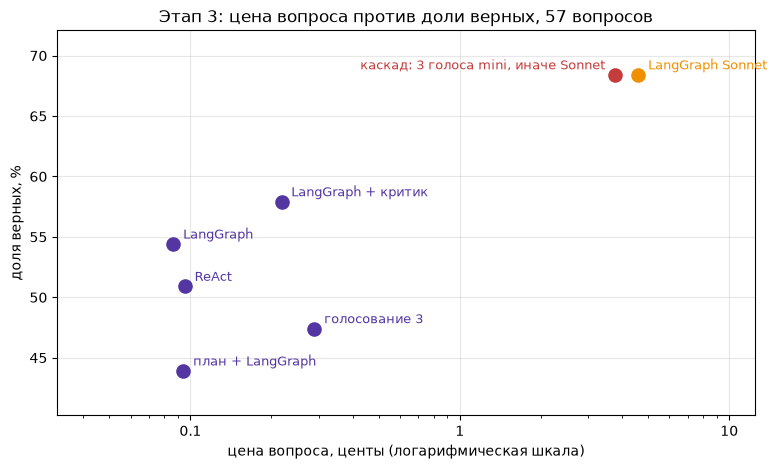

In [31]:
FINAL = [key("s3-1-ReAct + счётчик HTTP"), key("s3-3-LangGraph + счётчик HTTP"), key("s3-5-LangGraph + критик"), key("s3-6-голосование 3"),
         key("s3-8-план + LangGraph"), key("каскад: 3 голоса mini, иначе Sonnet", "mini + sonnet"), key("s3-7-LangGraph Sonnet", STRONG)]
final = report(FINAL)
ok = final["верно"].str.split("/").str[0].astype(int)
base = final.iloc[1]                                            # LangGraph на дешёвой модели
extra = ok - ok.iloc[1]
final["центов за дополнительный верный"] = ((final["центов на вопрос"] - base["центов на вопрос"]) * len(tasks) / extra).where(extra > 0).round(2)

fig, ax = plt.subplots(figsize=(9, 5))
ax.set_xscale("log")
for _, r in final.iterrows():
    cascade = r["вариант"].startswith("каскад")
    color = COLORS["red"] if cascade else COLORS["amber"] if "sonnet" in r["модель"] else COLORS["violet"]
    ax.scatter(r["центов на вопрос"], r["доля"] * 100, s=90, color=color, zorder=3)
    ax.annotate(re.sub(r"^s3-\d-| \+ счётчик HTTP", "", r["вариант"]), (r["центов на вопрос"], r["доля"] * 100),   # каскад подписан слева, чтобы не налезал на Sonnet
                xytext=(-7, 4) if cascade else (7, 4), ha="right" if cascade else "left", textcoords="offset points", fontsize=9, color=color)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:g}"))
ax.margins(x=0.25, y=0.15)
ax.set_xlabel("цена вопроса, центы (логарифмическая шкала)"); ax.set_ylabel("доля верных, %")
ax.set_title("Этап 3: цена вопроса против доли верных, 57 вопросов"); ax.grid(alpha=0.3)
fig.savefig(IMG / "money_quality.png", dpi=150, bbox_inches="tight")
final